# Task 02 – Build and Compare Machine Learning Models
**Dataset:** Loan Approval Prediction

## **Objective**
Develop multiple machine learning models for a real-world prediction problem and evaluate their performance using appropriate metrics.

Banks have to decide quickly whether an applicant is likely to be a safe borrower. Here I build a set of models that learn from past applications (income, credit score, assets, loan size) and predict whether a new loan will be approved or rejected, then I compare them side by side to see which one is most reliable.

## Technologies
Python

Pandas

NumPy

Scikit-learn

Matplotlib

Seaborn

The work uses the standard Python data stack. Preprocessing and models are wrapped in Scikit-learn Pipelines so every step is applied the same way during training and testing. XGBoost is included as the optional model.

In [1]:
!pip install -q kagglehub xgboost

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
RS = 7

## Dataset
Select any real-world dataset from Kaggle with at least 1,000 records.

The data is the Kaggle **Loan Approval Prediction Dataset**, about 4,200 applications. Every row is one applicant with their dependents, education, employment type, annual income, requested loan amount and term, CIBIL credit score and four kinds of asset value. The label "loan_status" says whether the loan was Approved or Rejected.

In [3]:
import kagglehub
try:
    path = kagglehub.dataset_download("architsharma01/loan-approval-prediction-dataset")
    csv = [f for f in os.listdir(path) if f.endswith(".csv")][0]
    raw = pd.read_csv(os.path.join(path, csv))
except Exception as err:
    print("Download problem:", err, "\nPlease upload the CSV by hand.")
    from google.colab import files
    up = files.upload()
    raw = pd.read_csv(list(up.keys())[0])

print(raw.shape)
raw.head()

100%|██████████| 80.6k/80.6k [00:00<00:00, 22.6MB/s]

Extracting files...
(4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
# column names and text values in this file contain stray spaces - tidy them first
raw.columns = raw.columns.str.strip()
for c in raw.select_dtypes("object"):
    raw[c] = raw[c].str.strip()

raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


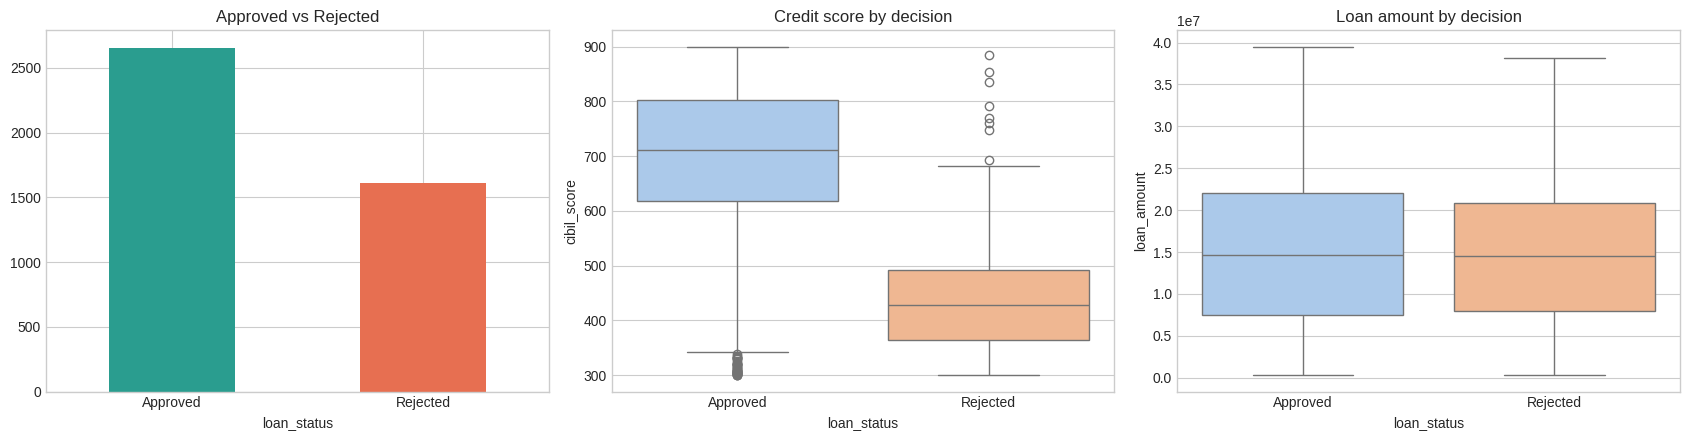

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
raw["loan_status"].value_counts().plot(kind="bar", color=["#2a9d8f", "#e76f51"], ax=axes[0], rot=0)
axes[0].set_title("Approved vs Rejected")
sns.boxplot(data=raw, x="loan_status", y="cibil_score", palette="pastel", ax=axes[1])
axes[1].set_title("Credit score by decision")
sns.boxplot(data=raw, x="loan_status", y="loan_amount", palette="pastel", ax=axes[2])
axes[2].set_title("Loan amount by decision")
plt.tight_layout(); plt.show()

## Part 1 – Data Preprocessing
Load the dataset, handle missing values, remove duplicates, encode categorical features, scale numerical features, split into training and testing sets.

I clean the table first (gaps, duplicates, useless ID column), add two engineered ratios, split the data, and let a "ColumnTransformer" scale the numbers and one-hot encode the text columns inside each model's pipeline.

In [6]:
data = raw.copy()

print("Missing cells:", int(data.isnull().sum().sum()))
data = data.dropna()

dups = data.duplicated().sum()
data = data.drop_duplicates()
print("Duplicate rows dropped:", dups)

# an ID carries no predictive signal
data = data.drop(columns=["loan_id"])
data["loan_status"] = data["loan_status"].map({"Approved": 1, "Rejected": 0})
print("Rows kept:", len(data))

Missing cells: 0
Duplicate rows dropped: 0
Rows kept: 4269


**Feature engineering:** "total_assets" adds up all four asset columns, and "loan_to_income" shows how large the loan is compared with a year of income. Lenders look at exactly these kinds of ratios, so they may help the models.

In [9]:
asset_cols = ["residential_assets_value", "commercial_assets_value", "luxury_assets_value", "bank_asset_value"]
data["total_assets"] = data[asset_cols].sum(axis=1)
data["loan_to_income"] = data["loan_amount"] / data["income_annum"]

y = data["loan_status"]
X = data.drop(columns="loan_status")

cat_features = ["education", "self_employed"]
num_features = [c for c in X.columns if c not in cat_features]

prep = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="first"), cat_features),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 3201 | Testing rows: 1068


## Part 2 – Model Development
Train at least three different machine learning algorithms (Logistic Regression, Decision Tree, Random Forest, KNN, SVM, XGBoost optional).

Approve/reject is a two-class decision, so I use six classification algorithms, each placed in a pipeline with the same preprocessing. Linear Regression predicts a continuous value, so I apply it in the bonus section instead.

In [10]:
def make(model):
    return Pipeline([("prep", prep), ("model", model)])

pipes = {
    "Logistic Regression": make(LogisticRegression(max_iter=2000, random_state=RS)),
    "Decision Tree":       make(DecisionTreeClassifier(max_depth=6, random_state=RS)),
    "Random Forest":       make(RandomForestClassifier(n_estimators=250, random_state=RS)),
    "KNN":                 make(KNeighborsClassifier(n_neighbors=11)),
    "SVM":                 make(SVC(kernel="rbf", C=1.0, random_state=RS)),
    "XGBoost":             make(XGBClassifier(n_estimators=250, learning_rate=0.1, max_depth=4,
                                              eval_metric="logloss", random_state=RS)),
}

durations = {}
for label, p in pipes.items():
    start = time.perf_counter()
    p.fit(X_train, y_train)
    durations[label] = time.perf_counter() - start
    print(f"{label:<20}{durations[label]:>8.3f} s")

Logistic Regression    0.039 s
Decision Tree          0.030 s
Random Forest          1.203 s
KNN                    0.017 s
SVM                    0.146 s
XGBoost                0.210 s


## Part 3 – Model Evaluation
Evaluate each model using Accuracy, Precision, Recall, F1 Score and Confusion Matrix (MAE, MSE, RMSE, R² for regression).

Each pipeline predicts on the held-out 25% of applications. For a lender, a wrongly approved bad loan is costly, so beyond accuracy I look at precision (how many approvals were correct) and recall (how many good applicants were found).

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
table = []
preds = {}
for label, p in pipes.items():
    preds[label] = p.predict(X_test)
    yp = preds[label]
    table.append(dict(
        Model=label,
        Accuracy=accuracy_score(y_test, yp),
        Precision=precision_score(y_test, yp),
        Recall=recall_score(y_test, yp),
        F1=f1_score(y_test, yp),
        CV_Accuracy=cross_val_score(p, X_train, y_train, cv=skf).mean(),
        Train_Seconds=durations[label],
    ))
scores = pd.DataFrame(table).set_index("Model").round(4)
scores.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,CV_Accuracy,Train_Seconds
Model,,,,,,
Random Forest,0.9953,0.9925,1.0000,0.9962,0.9959,1.2035
Decision Tree,0.9944,0.9925,0.9985,0.9955,0.9922,0.0303
XGBoost,0.9934,0.9910,0.9985,0.9947,0.9944,0.2097
SVM,0.9560,0.9611,0.9684,0.9647,0.9491,0.1463
Logistic Regression,0.9251,0.9465,0.9322,0.9393,0.9147,0.0394
KNN,0.9223,0.9278,0.9488,0.9382,0.9182,0.0167


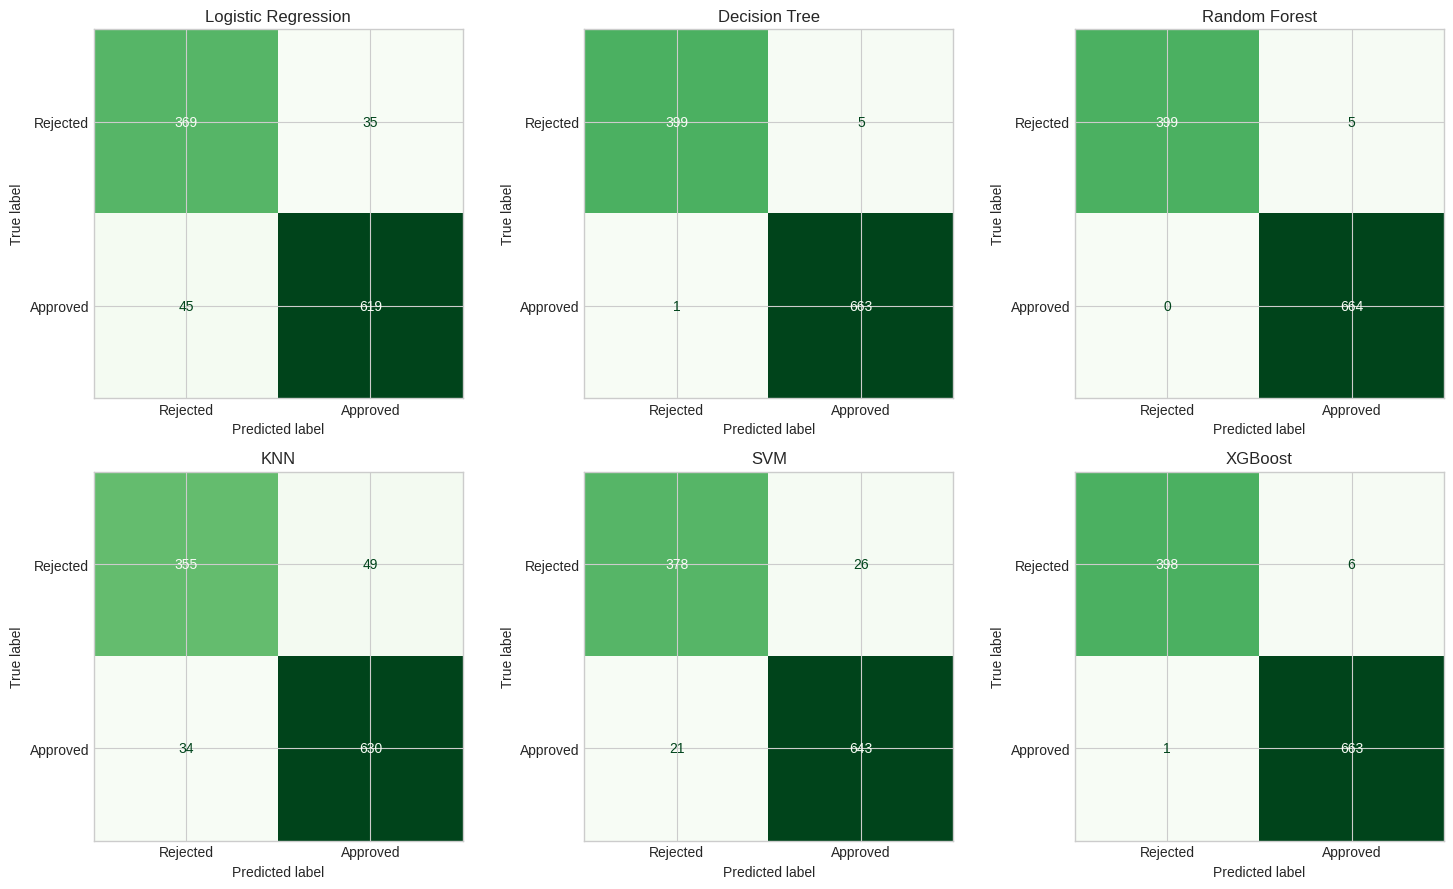

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (label, yp) in zip(axes.flat, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, yp, display_labels=["Rejected", "Approved"],
                                            cmap="Greens", colorbar=False, ax=ax)
    ax.set_title(label)
plt.tight_layout(); plt.show()

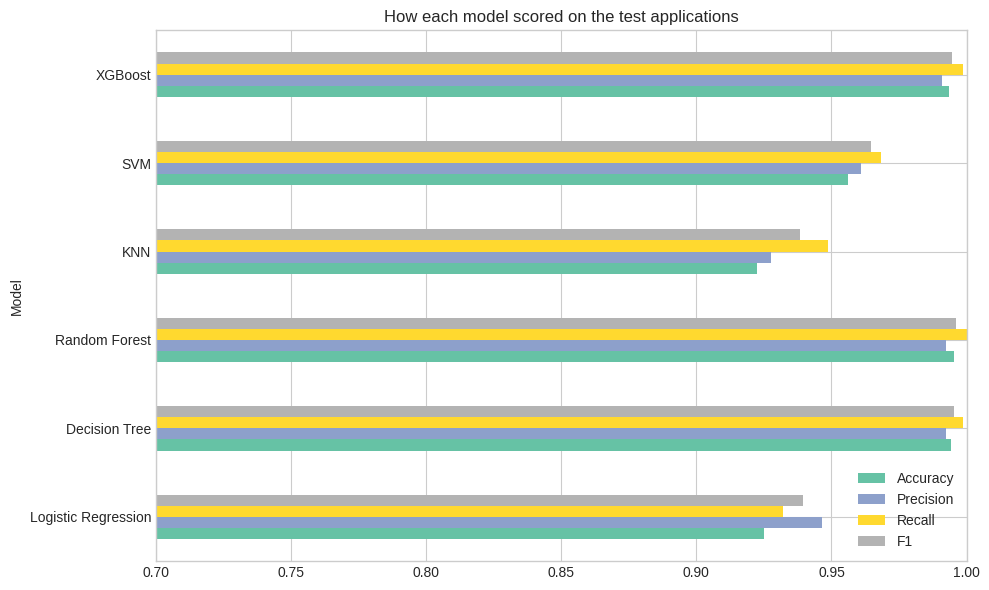

In [13]:
ax = scores[["Accuracy", "Precision", "Recall", "F1"]].plot.barh(figsize=(10, 6), colormap="Set2")
ax.set_xlim(0.7, 1.0); ax.set_title("How each model scored on the test applications")
plt.tight_layout(); plt.show()

## Part 4 – Model Comparison
Create a comparison table showing Model Name, Training Time, Evaluation Metrics, Advantages and Limitations.

All results are gathered into a single table. The pros and cons describe how each algorithm generally behaves on structured financial data.

In [14]:
pros_cons = {
    "Logistic Regression": ("Quick baseline, outputs probabilities, easy to justify to a customer.",
                            "Only draws linear boundaries, so it can miss non-linear credit patterns."),
    "Decision Tree":       ("Clear if-then rules that match how credit policies are written.",
                            "A single deep tree memorises noise and is unstable."),
    "Random Forest":       ("Robust, handles non-linear effects, gives feature importance.",
                            "Heavier model; less transparent than one tree."),
    "KNN":                 ("Needs no real training and is intuitive.",
                            "Prediction slows as data grows; weak when features have different scales or noise."),
    "SVM":                 ("Works well on cleanly separable data with scaled features.",
                            "Slow on bigger data and hard to interpret."),
    "XGBoost":             ("Usually the most accurate on tabular data; handles complex interactions.",
                            "More settings to tune; can overfit if left unchecked."),
}
final = scores.copy()
final["Advantages"] = final.index.map(lambda m: pros_cons[m][0])
final["Limitations"] = final.index.map(lambda m: pros_cons[m][1])
pd.set_option("display.max_colwidth", None)
final.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,CV_Accuracy,Train_Seconds,Advantages,Limitations
Model,,,,,,,,
Random Forest,0.9953,0.9925,1.0000,0.9962,0.9959,1.2035,"Robust, handles non-linear effects, gives feature importance.",Heavier model; less transparent than one tree.
Decision Tree,0.9944,0.9925,0.9985,0.9955,0.9922,0.0303,Clear if-then rules that match how credit policies are written.,A single deep tree memorises noise and is unstable.
XGBoost,0.9934,0.9910,0.9985,0.9947,0.9944,0.2097,Usually the most accurate on tabular data; handles complex interactions.,More settings to tune; can overfit if left unchecked.
SVM,0.9560,0.9611,0.9684,0.9647,0.9491,0.1463,Works well on cleanly separable data with scaled features.,Slow on bigger data and hard to interpret.
Logistic Regression,0.9251,0.9465,0.9322,0.9393,0.9147,0.0394,"Quick baseline, outputs probabilities, easy to justify to a customer.","Only draws linear boundaries, so it can miss non-linear credit patterns."
KNN,0.9223,0.9278,0.9488,0.9382,0.9182,0.0167,Needs no real training and is intuitive.,Prediction slows as data grows; weak when features have different scales or noise.


## Part 5 – Conclusion
Recommend the best-performing model and explain why it performed better.

The top model is selected by F1 score, and I then discuss the reason for its lead.

In [15]:
winner = scores["F1"].idxmax()
w = scores.loc[winner]
print(f"Recommended model: {winner}")
print(f"  Accuracy  : {w['Accuracy']:.3f}")
print(f"  Precision : {w['Precision']:.3f}")
print(f"  Recall    : {w['Recall']:.3f}")
print(f"  F1        : {w['F1']:.3f}")
print(f"  5-fold CV : {w['CV_Accuracy']:.3f}")

Recommended model: Random Forest
  Accuracy  : 0.995
  Precision : 0.993
  Recall    : 1.000
  F1        : 0.996
  5-fold CV : 0.996


**Reasoning:** the recommended model leads on F1 and its cross-validated accuracy matches its test accuracy, which suggests it generalises instead of memorising. Credit score and the loan-to-income ratio carry most of the decision signal, and models that can capture non-linear splits on those features (tree ensembles) tend to beat distance-based or purely linear ones here.

**Caveat:** this is historical data, so a real lender would also check fairness across applicant groups before deploying any model.

## Bonus – Hyperparameter Tuning
Perform Hyperparameter Tuning using GridSearchCV or RandomizedSearchCV.

Instead of trying every combination, **RandomizedSearchCV** samples 20 random settings of XGBoost and scores each with cross-validation, which is faster than a full grid.

In [16]:
space = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
}
search = RandomizedSearchCV(pipes["XGBoost"], space, n_iter=20, cv=skf, scoring="f1",
                            random_state=RS, n_jobs=-1)
t0 = time.perf_counter(); search.fit(X_train, y_train)
print(f"Tuning time: {time.perf_counter()-t0:.1f}s")
print("Best settings:", search.best_params_)
print(f"Best CV F1  : {search.best_score_:.4f}")

yp = search.best_estimator_.predict(X_test)
print(f"\nTest F1  before: {scores.loc['XGBoost','F1']:.4f}  after: {f1_score(y_test, yp):.4f}")
print(f"Test Acc before: {scores.loc['XGBoost','Accuracy']:.4f}  after: {accuracy_score(y_test, yp):.4f}")

Tuning time: 22.9s
Best settings: {'model__subsample': 0.7, 'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}
Best CV F1  : 0.9958

Test F1  before: 0.9947  after: 0.9947
Test Acc before: 0.9934  after: 0.9934


### Extra: Linear Regression for loan amount
Because Linear Regression outputs a number, I use it to estimate the requested `loan_amount` from the applicant's other numeric details and report the regression metrics.

In [17]:
num_only = data[["no_of_dependents", "income_annum", "loan_term", "cibil_score", "total_assets"]]
target = data["loan_amount"]
a_tr, a_te, b_tr, b_te = train_test_split(num_only, target, test_size=0.25, random_state=RS)

reg = Pipeline([("sc", StandardScaler()), ("lr", LinearRegression())]).fit(a_tr, b_tr)
out = reg.predict(a_te)
err = mean_squared_error(b_te, out)

print(f"MAE  : {mean_absolute_error(b_te, out):,.0f}")
print(f"MSE  : {err:,.0f}")
print(f"RMSE : {np.sqrt(err):,.0f}")
print(f"R²   : {r2_score(b_te, out):.3f}")

MAE  : 2,481,564
MSE  : 10,792,570,834,243
RMSE : 3,285,205
R²   : 0.870
